# Лабораторная работа 3. Кластерный анализ методом DBSCAN

### Задание
Для каждого набора данных:

1. определить число кластеров и обосновать свой выбор;
2. разбить объекты на кластеры, предложить и обосновать интерпретацию кластеров.

Для DBSCAN число кластеров не задаётся, а определяется параметрами плотности `eps` и `min_samples`; их выбор и является основной задачей.

### План
Часть A (леденцы) и часть B (цифры): разведочный анализ → k-distance график → перебор параметров и выбор по плато → результат, шум → устойчивость → интерпретация → сопоставление с методами ЛР 1 и ЛР 2.

## 0. Подготовка окружения и загрузка данных

In [1]:
import sys, platform, warnings, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import FactorAnalysis
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10, "axes.titlesize": 11, "figure.max_open_warning": 0})
pd.set_option("display.width", 160, "display.max_columns", 40, "display.precision", 3)

In [2]:
CANDY_PATH = "/content/Леденцы.dat"
DIGITS_PATH = "/content/digit.dat"

print("Леденцы:", CANDY_PATH, "| Цифры:", DIGITS_PATH)

Леденцы: /content/Леденцы.dat | Цифры: /content/digit.dat


In [3]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
FIG_PREFIX = "fig"

def save_show(fig, name, tight=True):
    if tight:
        fig.tight_layout()
    fig.savefig(FIG_DIR / f"{FIG_PREFIX}_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def heatmap(ax, M, xt, yt, fmt="{:.2f}", cmap="RdBu_r", vmin=None, vmax=None, annot=True, fontsize=8):
    M = np.asarray(M, float)
    vmin = np.nanmin(M) if vmin is None else vmin
    vmax = np.nanmax(M) if vmax is None else vmax
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=45, ha="right")
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt)
    ax.grid(False)
    if annot:
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                t = (M[i, j] - vmin) / (vmax - vmin + 1e-12)
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=fontsize,
                        color="white" if (t < 0.2 or t > 0.8) else "black")
    return im

In [4]:
def internal_scores(X, labels, metric="euclidean"):
    return dict(silhouette=silhouette_score(X, labels, metric=metric),
                calinski_harabasz=calinski_harabasz_score(X, labels),
                davies_bouldin=davies_bouldin_score(X, labels))

def fit_kmeans(X, k, n_init=50, seed=SEED):
    return KMeans(n_clusters=k, n_init=n_init, init="k-means++", random_state=seed).fit(X)

def gap_statistic(X, ks, B=50, seed=SEED):
    rng = np.random.default_rng(seed)
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    Xp = Xc @ Vt.T
    lo, hi = Xp.min(0), Xp.max(0)
    def logW(M, k):
        return np.log(KMeans(k, n_init=5, random_state=seed).fit(M).inertia_)
    obs = np.array([logW(Xp, k) for k in ks])
    ref = np.array([[logW(rng.uniform(lo, hi, size=Xp.shape), k) for k in ks] for _ in range(B)])
    gap = ref.mean(0) - obs
    s = ref.std(0, ddof=0) * np.sqrt(1 + 1 / B)
    return pd.DataFrame({"gap": gap, "s": s}, index=list(ks))

def subsample_stability(X, k, method, ref_labels, n_rep=100, frac=0.8, seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for r in range(n_rep):
        idx = rng.choice(len(X), int(frac * len(X)), replace=False)
        if method == "kmeans":
            lab = KMeans(k, n_init=10, random_state=r).fit_predict(X[idx])
        else:
            lab = fcluster(linkage(X[idx], "ward"), k, "maxclust")
        out.append(adjusted_rand_score(ref_labels[idx], lab))
    return np.mean(out), np.std(out)

# Часть A. Данные «Леденцы»

In [5]:
FIG_PREFIX = "candies"
DATA_PATH = CANDY_PATH

## A.1. Описание данных и разведочный анализ

In [6]:
raw = pd.read_csv(DATA_PATH, sep=";")
VARS = list(raw.columns)

VAR_TEXT = {
    "V1": "освежить дыхание",
    "V2": "чувствовать себя увереннее",
    "V3": "освежить полость рта",
    "V4": "избавиться от неприятного вкуса во рту",
    "V5": "как заменитель других кондитерских изделий",
    "V6": "когда хочется чего-нибудь сладкого",
    "V7": "помогают сконцентрироваться",
    "V8": "отвлечься на несколько минут и подумать",
    "V9": "облегчить боль в горле",
    "V10": "избавиться от заложенности носа",
    "V11": "улучшение самочувствия",
}
print("Размер выборки:", raw.shape)
display(raw.head())

Размер выборки: (338, 11)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


На этапе предварительного анализа данных проводится верификация следующих характеристик:

* наличие пропущенных значений;
* типы данных;
* диапазоны шкальных измерений;
* наличие дубликатов;
* структура корреляционных связей.

Совокупность полученных результатов определяет выбор подходящей метрики расстояния, обосновывает необходимость стандартизации признакового пространства и задает оптимальные параметры для алгоритма кластеризации DBSCAN.

In [7]:
print("Пропусков:", int(raw.isna().sum().sum()))
print("Типы столбцов:", raw.dtypes.unique().tolist())
print("Минимум / максимум по всей таблице:", raw.min().min(), "/", raw.max().max())

freq = raw.apply(lambda s: s.value_counts()).fillna(0).astype(int).sort_index()
display(freq.T)

Пропусков: 0
Типы столбцов: [dtype('int64')]
Минимум / максимум по всей таблице: 2 / 5


,2,3,4,5
V1,19,209,17,93
V2,24,200,26,88
V3,31,193,22,92
V4,50,174,39,75
V5,47,226,13,52
V6,48,225,13,52
V7,34,238,12,54
V8,25,244,15,54
V9,15,207,13,103
V10,15,210,25,88


**Наблюдения:**

* Пропущенные значения в массиве данных отсутствуют.
* Все 11 переменных имеют целочисленный тип и принимают значения в диапазоне от 2 до 5; минимальная градация (1) не зафиксирована, что свидетельствует о фактическом использовании четырехбалльной шкалы.
* Переменные измерены в единой шкале, в связи с чем процедура стандартизации не требуется.
* Исходная порядковая шкала в рамках исследования трактуется как интервальная.

In [8]:
n = len(raw)
n_dup = int(raw.duplicated().sum())
patterns = raw.value_counts().rename("n").reset_index()
print(f"Строк: {n};  повторяющихся строк: {n_dup} ({n_dup/n:.1%});  уникальных профилей ответов: {len(patterns)}")
print("Покрытие выборки 4 самыми частыми профилями:", f"{patterns['n'].head(4).sum()/n:.1%}")
display(patterns.head(8))

Строк: 338;  повторяющихся строк: 293 (86.7%);  уникальных профилей ответов: 45
Покрытие выборки 4 самыми частыми профилями: 55.3%


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,n
0,3,3,3,3,3,3,5,5,3,3,3,52
1,3,3,3,3,3,3,3,3,5,5,5,49
2,5,5,5,5,3,3,3,3,3,3,3,49
3,3,3,3,3,5,5,3,3,3,3,3,37
4,3,3,3,2,2,2,2,2,5,5,5,15
5,5,5,5,4,3,3,3,3,3,3,3,12
6,3,3,3,3,5,5,3,3,2,2,2,10
7,4,5,5,5,3,3,3,3,3,3,3,10


**Важное свойство данных:**

В выборке объемом 338 респондентов зафиксирована высокая концентрация эмпирических данных: при общем числе вариантов сформировано лишь 45 уникальных профилей ответов, причем на долю четырех наиболее частотных приходится более 55 % наблюдений. Данная закономерность свидетельствует о высокой вероятности наличия чётко выраженной кластерной структуры.

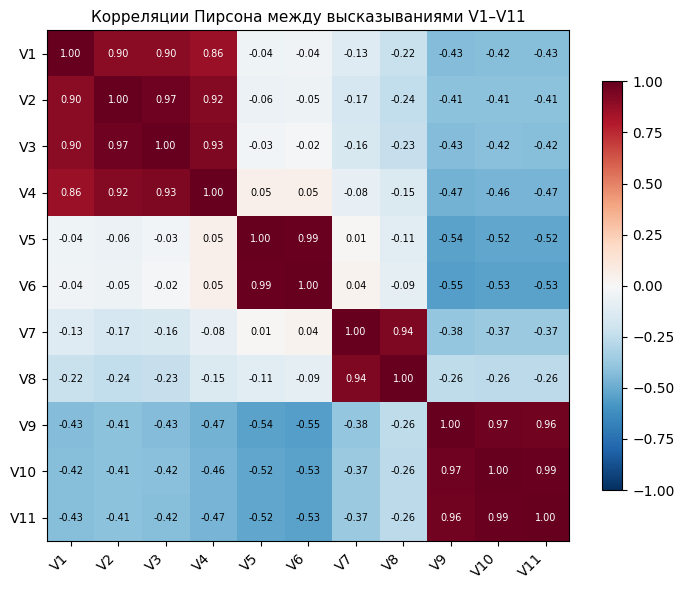

In [9]:
corr = raw.corr()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = heatmap(ax, corr.values, VARS, VARS, cmap="RdBu_r", vmin=-1, vmax=1, fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Корреляции Пирсона между высказываниями V1–V11")
save_show(fig, "corr")

**Блочная структура данных:**

Анализ корреляционной матрицы демонстрирует деление переменных на четыре обособленных блока с высокой внутригрупповой связностью (коэффициент корреляции $|\mathbf{r}| \approx 0,86–0,99$):

| Блок | Переменные | Содержательная интерпретация |
| :--- | :--- | :--- |
| **Освежение** | V1–V4 | Свежесть дыхания, гигиена полости рта, устранение неприятного привкуса, уверенность |
| **Сладкое** | V5–V6 | Замещение кондитерских изделий / сладкого |
| **Концентрация** | V7–V8 | Повышение концентрации внимания, функциональная пауза |
| **Здоровье** | V9–V11 | Облегчение боли в горле, устранение заложенности носа, улучшение общего самочувствия |

Межблочные корреляционные связи близки к нулю или имеют отрицательные значения, что свидетельствует о взаимоисключающем характере мотивационных выборов: респондент, ориентированный на реализацию одной цели, как правило, не выбирает остальные. Данная особенность предвосхищает четкую сегментацию выборки по доминирующей целевой установке. Сформированные блоки используются в дальнейшем **исключительно на этапе качественной интерпретации**, но не на этапе кластеризации.

In [10]:
BLOCKS = {
    "Свежесть":  ["V1", "V2", "V3", "V4"],
    "Сладкое":   ["V5", "V6"],
    "Фокус":     ["V7", "V8"],
    "Здоровье":  ["V9", "V10", "V11"],
}
SEG_ORDER = list(BLOCKS)

X = raw.to_numpy(dtype=float)
N = len(X)
print("X:", X.shape)

X: (338, 11)


## A.2. Подбор параметров DBSCAN

Алгоритм плотностной кластеризации *DBSCAN* идентифицирует области высокой локальной концентрации объектов, квалифицируя разреженные точки как шум, присваивая им метку `-1`. Функционирование модели определяют два ключевых параметра: радиус окрестности `eps` и пороговое число объектов в окрестности `min_samples`, включая исследуемую точку и ее полные дубликаты.

* **Обоснование параметра `min_samples`:** Согласно общепринятым академическим рекомендациям (Ester et al., 1996), нижняя граница рассчитывается по формуле `min_samples >= D + 1`, где $D$ — размерность признакового пространства. Для рассматриваемого массива с $D = 11$ базовая величина составляет `min_samples = 12`. Анализ чувствительности модели к вариации данного показателя представлен ниже.
* **Специфика выбора `eps` на дискретных данных:** Поскольку исходные переменные принимают строго целые значения, попарные евклидовы расстояния между объектами описываются дискретной функцией вида $\sqrt{m}$, где $m \in \mathbb{N}$ — сумма квадратных отклонений. Соответственно, непрерывная подгонка радиуса `eps` нецелесообразна: результаты остаются неизменными внутри интервалов и изменяются исключительно дискретными «ступенями» $\sqrt{1}, \sqrt{2}, \sqrt{3}, \dots$.

In [11]:
K_RANGE = list(range(2, 11))
Z = linkage(X, "ward")
labels_ward = fcluster(Z, 4, "maxclust") - 1
labels_km = fit_kmeans(X, 4, n_init=100).labels_

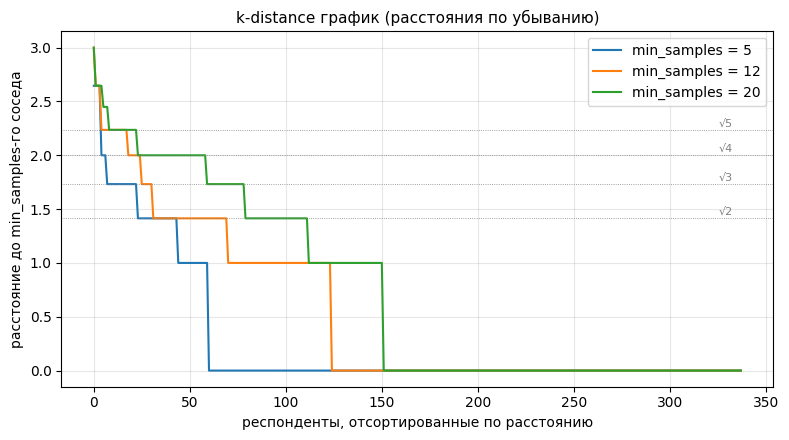

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for ms in (5, 12, 20):
    d_k = np.sort(NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)[0][:, -1])[::-1]
    ax.plot(d_k, label=f"min_samples = {ms}")
for m in (2, 3, 4, 5):
    ax.axhline(np.sqrt(m), color="grey", lw=0.6, ls=":")
    ax.text(N * 0.985, np.sqrt(m) + 0.03, f"√{m}", ha="right", fontsize=8, color="grey")
ax.set(title="k-distance график (расстояния по убыванию)", xlabel="респонденты, отсортированные по расстоянию",
       ylabel="расстояние до min_samples-го соседа")
ax.legend()
save_show(fig, "kdist")

Из-за дискретного характера исходных признаков и наличия множественных повторяющихся профилей график расстояний до 12-го соседа имеет ступенчатую форму и **не содержит выраженного излома**. Для основной массы респондентов значения находятся в интервале $\sqrt{1}–\sqrt{3}$, тогда как у изолированной группы пограничных наблюдений они превышают $\sqrt{4}$. В связи с этим прямое графическое определение `eps` оказывается неэффективным, а выбор гиперпараметра осуществляется путем сеточного поиска с выявлением устойчивых плато.

In [13]:
EPS_GRID = [np.sqrt(m) + 1e-6 for m in range(1, 13)]
MS_GRID = [5, 8, 10, 12, 15, 20, 30]

def run_dbscan(eps, ms):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    core = lab != -1
    k = len(set(lab[core]))
    sil = silhouette_score(X[core], lab[core]) if k >= 2 and core.sum() > k else np.nan
    return lab, k, 1 - core.mean(), sil

rows = []
for m_, eps in zip(range(1, 13), EPS_GRID):
    for ms in MS_GRID:
        _, k, noise, sil = run_dbscan(eps, ms)
        rows.append({"eps": f"√{m_}={np.sqrt(m_):.2f}", "min_samples": ms, "k": k, "шум": noise, "силуэт": sil})
grid = pd.DataFrame(rows)
order = list(dict.fromkeys(grid.eps))
for col, title in (("k", "Число кластеров"), ("шум", "Доля шума"), ("силуэт", "Силуэт (без шума)")):
    print(title)
    display(grid.pivot(index="eps", columns="min_samples", values=col).loc[order])

Число кластеров


min_samples,5,8,10,12,15,20,30
eps,,,,,,,
√1=1.00,9,8,7,6,6,4,4
√2=1.41,8,7,7,7,6,4,4
√3=1.73,4,4,4,4,4,5,4
√4=2.00,3,3,3,3,3,3,3
√5=2.24,3,3,3,3,3,3,3
√6=2.45,2,2,2,2,2,2,2
√7=2.65,2,2,2,2,2,2,2
√8=2.83,1,1,1,1,1,1,1
√9=3.00,1,1,1,1,1,1,1


Доля шума


min_samples,5,8,10,12,15,20,30
eps,,,,,,,
√1=1.00,0.130,0.148,0.175,0.204,0.204,0.296,0.322
√2=1.41,0.056,0.086,0.086,0.086,0.130,0.222,0.222
√3=1.73,0.018,0.030,0.030,0.030,0.030,0.036,0.038
√4=2.00,0.012,0.012,0.012,0.012,0.012,0.015,0.015
√5=2.24,0.012,0.012,0.012,0.012,0.012,0.012,0.012
√6=2.45,0.012,0.012,0.012,0.012,0.012,0.012,0.012
√7=2.65,0.000,0.000,0.000,0.000,0.000,0.000,0.000
√8=2.83,0.000,0.000,0.000,0.000,0.000,0.000,0.000
√9=3.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Силуэт (без шума)


min_samples,5,8,10,12,15,20,30
eps,,,,,,,
√1=1.00,0.898,0.896,0.908,0.905,0.905,0.911,0.929
√2=1.41,0.786,0.812,0.812,0.812,0.825,0.854,0.854
√3=1.73,0.737,0.745,0.745,0.745,0.745,0.638,0.749
√4=2.00,0.620,0.620,0.620,0.620,0.620,0.622,0.622
√5=2.24,0.620,0.620,0.620,0.620,0.620,0.620,0.620
√6=2.45,0.458,0.458,0.458,0.458,0.458,0.458,0.458
√7=2.65,0.455,0.455,0.455,0.455,0.455,0.455,0.455
√8=2.83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
√9=3.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Интерпретация табличных данных и критерии селекции гиперпараметров

* **Режим избыточной фрагментации ($\mathtt{eps} \le \sqrt{2} \approx 1{,}41$):** При малых значениях радиуса окрестности и `min_samples` $\le 15$ алгоритм расщепляет структуру на $6–9$ локальных мелкомасштабных кластеров при высоком уровне шума ($6–20\,\%$). Увеличение `min_samples` $\ge 20$ приводит к формированию 4 кластеров, однако сопровождается отсевом $22–32\,\%$ точек в категорию шума. Высокие показатели коэффициента силуэта ($0{,}80–0{,}93$) на данном интервале являются **фиктивно завышенными**, поскольку рассчитываются без учета шума на группах из практически идентичных наблюдений.
* **Область оптимального равновесия ($\mathtt{eps} = \sqrt{3} \approx 1{,}73$):** Устойчиво формируются **4 кластера** при минимальной доле шума ($\approx 2–4\,\%$) для широкого диапазона `min_samples` от $5$ до $15$, а также при $30$ (исключение составляет `min_samples` $= 20$, где выделяется 5 групп).
* **Режим агломерации и слияния ($\mathtt{eps} \ge 2$):** Происходит объединение смежных областей плотности до $k = 3$, при $\mathtt{eps} \ge \sqrt{6} \approx 2{,}45$ число кластеров сокращается до 2, а при $\mathtt{eps} \ge \sqrt{8} \approx 2{,}83$ весь массив данных объединяется в единый кластер.

**Формальное правило выбора гиперпараметров:**
В качестве оптимальной принята конфигурация с **минимальным значением $\mathtt{eps}$, обеспечивающим уровень шума не более $5\,\%$** (что гарантирует максимальную локализацию плотности без избыточного отсева точек) при базом значении `min_samples` $= 12$.

## A.3. Итоговое разбиение DBSCAN

In [14]:
MS_FINAL = 12
chosen = None
for m_, eps in zip(range(1, 13), EPS_GRID):
    lab, k, noise, sil = run_dbscan(eps, MS_FINAL)
    if noise <= 0.05 and k >= 2:
        chosen = (m_, eps, lab, k, noise, sil); break
m_, EPS_FINAL, labels_db, k_db, noise_db, sil_db = chosen
print(f"Выбрано: eps = √{m_} ≈ {np.sqrt(m_):.3f}, min_samples = {MS_FINAL}")
print(f"Кластеров: {k_db};  шум: {(labels_db == -1).sum()} респондентов ({noise_db:.1%});  силуэт без шума: {sil_db:.3f}")
print("Размеры кластеров:", {int(c): int((labels_db == c).sum()) for c in sorted(set(labels_db))})

core = labels_db != -1
print("ARI(DBSCAN, k-means) на неотброшенных точках:", round(adjusted_rand_score(labels_db[core], labels_km[core]), 4))
print("\nПрофили респондентов, признанных шумом:")
display(raw[labels_db == -1].value_counts().rename("n").reset_index())

Выбрано: eps = √3 ≈ 1.732, min_samples = 12
Кластеров: 4;  шум: 10 респондентов (3.0%);  силуэт без шума: 0.745
Размеры кластеров: {-1: 10, 0: 110, 1: 100, 2: 61, 3: 57}
ARI(DBSCAN, k-means) на неотброшенных точках: 1.0

Профили респондентов, признанных шумом:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,n
0,2,2,2,2,2,2,4,4,5,5,5,3
1,2,4,4,4,2,2,2,3,5,5,5,3
2,3,2,2,2,2,3,5,5,3,3,3,2
3,2,2,2,2,2,2,4,4,5,4,4,1
4,2,4,4,4,2,2,2,3,5,4,4,1


### Выводы по части А лабораторной работы № 3

Алгоритм плотностной кластеризации *DBSCAN* при конфигурации параметров $\mathtt{eps} = \sqrt{3}$ ($\approx 1{,}73$) и $\mathtt{min\_samples} = 12$ выступает в качестве независимого подтверждения устойчивости **4-кластерной структуры**. На подвыборке неотброшенных наблюдений сформированное разбиение демонстрирует абсолютную эквивалентность с результатами алгоритма $k$-средних ($ARI = 1{,}00$).

В категорию шума отнесено 10 респондентов ($3{,}0\,\%$ от объема выборки):
* **8 наблюдений** характеризуются одновременным ростом оценок по мотивам из смежных блоков (сочетание «Здоровья» со «Свежестью» или «Фокусом»), геометрически располагаясь в промежуточных областях между ясными сегментами;
* **2 наблюдения** образуют редкую изолированную спецификацию («Фокус» с полным неприятием альтернативных целей потребления).

**Ключевые методические ограничения DBSCAN на рассматриваемых данных:**
* **Высокая чувствительность к радиусу окрестности ($\mathtt{eps}$):** наблюдаются дискретные пороговые переходы количества сформированных кластеров ($6–9 \rightarrow 4 \rightarrow 3 \rightarrow 2 \rightarrow 1$) при незначительном изменении параметра.
* **Проблема классификации шума:** возникает необходимость в дополнительных методических процедурах для содержательной интерпретации и последующей агломерации отброшенных объектов к базовым сегментам.

## A.4. Устойчивость и работа с шумом

In [15]:
print(f"Доля комбинаций (eps, min_samples) на сетке, дающих 4 кластера: {(grid.k == 4).mean():.1%} ({int((grid.k == 4).sum())} из {len(grid)})")
print("При eps = √3:", grid[grid.eps.str.startswith('√3=')].set_index('min_samples').k.to_dict())

rng = np.random.default_rng(SEED)
aris, noises = [], []
for _ in range(100):
    idx = rng.choice(N, int(0.8 * N), replace=False)
    lab_s = DBSCAN(eps=EPS_FINAL, min_samples=MS_FINAL).fit_predict(X[idx])
    both = (lab_s != -1) & (labels_db[idx] != -1)
    aris.append(adjusted_rand_score(labels_db[idx][both], lab_s[both])); noises.append((lab_s == -1).mean())
print(f"Устойчивость к подвыборкам: средний ARI = {np.mean(aris):.3f} ± {np.std(aris):.3f}; средняя доля шума на подвыборках = {np.mean(noises):.1%}")

ids = np.array(sorted(set(labels_db) - {-1}))
centroids = np.array([X[labels_db == c].mean(0) for c in ids])
labels_full = labels_db.copy()
d2 = ((X[labels_db == -1][:, None, :] - centroids[None]) ** 2).sum(-1)
labels_full[labels_db == -1] = ids[d2.argmin(1)]
print("ARI(DBSCAN с шумом, k-средних):", round(adjusted_rand_score(labels_full, labels_km), 4))
print("Кластеры, в которые попали шумовые респонденты:", pd.Series(labels_full[labels_db == -1]).value_counts().sort_index().to_dict())

Доля комбинаций (eps, min_samples) на сетке, дающих 4 кластера: 11.9% (10 из 84)
При eps = √3: {5: 4, 8: 4, 10: 4, 12: 4, 15: 4, 20: 5, 30: 4}
Устойчивость к подвыборкам: средний ARI = 0.970 ± 0.048; средняя доля шума на подвыборках = 3.4%
ARI(DBSCAN с шумом, k-средних): 1.0
Кластеры, в которые попали шумовые респонденты: {1: 8, 3: 2}


### Анализ устойчивости

**Параметрическая чувствительность:**
Алгоритм *DBSCAN* демонстрирует выраженную чувствительность к выборку радиуса окрестности $\mathtt{eps}$: 4-кластерная конфигурация воспроизводится только в узком интервале пространства параметров — на 10 из 84 протестированных комбинаций ($11{,}9\,\%$ от общего объема сетки). При фиксированном радиусе $\mathtt{eps} = \sqrt{3}$ структура из четырех кластеров сохраняется при $\mathtt{min\_samples} \in \{5, 8, 10, 12, 15, 30\}$ (исключением является значение $\mathtt{min\_samples} = 20$, при котором один из сегментов расщепляется, формируя 5 групп). Отклонение от указанного радиуса приводит к скачкообразной трансформации структуры ($6–9 \rightarrow 3 \rightarrow 2 \rightarrow 1$).

**Устойчивость при фиксированных параметрах:**
При зафиксированных оптимизированных гиперпараметрах модель демонстрирует высочайшую стабильность к процедурам ресамплинга: на $80\,\%$-ных подвыборках среднее значение индекса Ранда составляет $ARI = 0{,}970 \pm 0{,}048$ при стабильной доле шума $3{,}4\,\%$.

**Интеграция с базовыми алгоритмами:**
Применение процедуры доклассификации шумовых наблюдений по принципу минимального евклидова расстояния до ближайшего центроида приводит к **абсолютному совпадению** полученной структуры с результатами $k$-средних и метода Уорда ($ARI = 1{,}00$). При этом 8 шумовых респондентов перераспределяются в сегмент «Здоровье», а оставшиеся 2 — в сегмент «Фокус».

## A.5. Интерпретация сегментов

Средний силуэт (без шума): 0.745;  респондентов с отрицательным силуэтом: 0 из 328


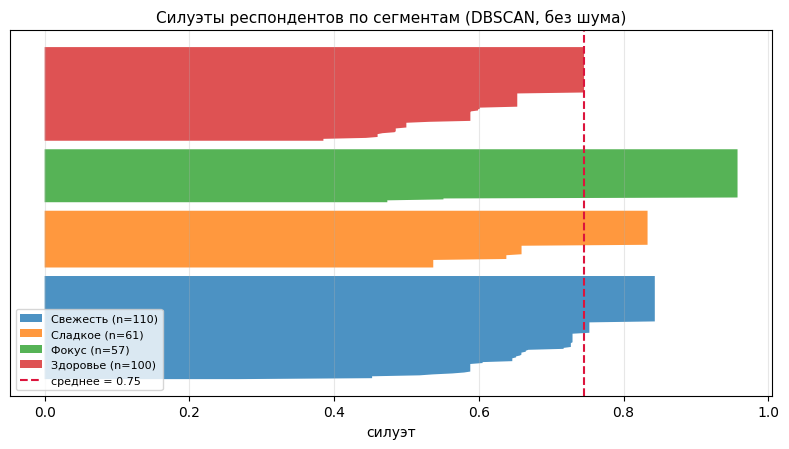

In [16]:
def name_clusters(labels, X=X, X_ref=X):
    names = {}
    for c in sorted(set(labels) - {-1}):
        centre = X[labels == c].mean(0)
        score = {b: np.mean([centre[VARS.index(v)] - X_ref[:, VARS.index(v)].mean() for v in vs]) for b, vs in BLOCKS.items()}
        names[c] = max(score, key=score.get)
    assert len(set(names.values())) == len(names), "два кластера получили одно имя — проверить разбиение"
    if -1 in labels:
        names[-1] = "Шум"
    return names

seg_db = pd.Series(labels_db).map(name_clusters(labels_db))
core = labels_db != -1

sil_i = np.full(N, np.nan)
sil_i[core] = silhouette_samples(X[core], labels_db[core])
print(f"Средний силуэт (без шума): {np.nanmean(sil_i):.3f};  респондентов с отрицательным силуэтом: {int((sil_i[core] < 0).sum())} из {int(core.sum())}")

fig, ax = plt.subplots(figsize=(8, 4.6))
y0 = 0
for seg in SEG_ORDER:
    v = np.sort(sil_i[(seg_db == seg).to_numpy()])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.8, label=f"{seg} (n={len(v)})")
    y0 += len(v) + 8
ax.axvline(np.nanmean(sil_i), color="crimson", ls="--", label=f"среднее = {np.nanmean(sil_i):.2f}")
ax.set(title="Силуэты респондентов по сегментам (DBSCAN, без шума)", xlabel="силуэт", yticks=[])
ax.legend(loc="lower left", fontsize=8)
save_show(fig, "silhouette")

### Профили сегментов

In [17]:
res = raw.copy()
res["сегмент"] = pd.Categorical(seg_db.where(seg_db.isin(SEG_ORDER)), categories=SEG_ORDER, ordered=True)

size = res["сегмент"].value_counts().reindex(SEG_ORDER)
profile = res.groupby("сегмент", observed=True)[VARS].mean().reindex(SEG_ORDER)
print("Размеры сегментов:")
display(pd.DataFrame({"n": size, "доля": size / N}).T)
print("Средние оценки по высказываниям:")
display(pd.concat([profile, raw.mean().rename("вся выборка").to_frame().T]))

top2 = res.groupby("сегмент", observed=True)[VARS].agg(lambda s: (s >= 4).mean()).reindex(SEG_ORDER)
print("Доля респондентов, согласных с высказыванием:")
display(top2)

Размеры сегментов:


сегмент,Свежесть,Сладкое,Фокус,Здоровье
n,110.000,61.00,57.000,100.000
доля,0.325,0.18,0.169,0.296


Средние оценки по высказываниям:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Свежесть,4.845,4.800,4.836,4.682,3.036,3.036,3.000,2.991,3.073,3.045,3.045
Сладкое,3.000,3.000,3.000,3.000,4.852,4.852,3.000,2.918,2.754,2.754,2.754
Фокус,3.000,3.000,3.000,2.947,2.947,2.947,4.912,4.912,3.000,3.000,3.000
Здоровье,2.890,2.820,2.750,2.590,2.660,2.630,2.730,2.870,4.950,4.820,4.870
вся выборка,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565


Доля респондентов, согласных с высказыванием:


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
сегмент,,,,,,,,,,,
Свежесть,1.0,1.0,1.0,1.0,0.036,0.036,0.00,0.027,0.073,0.045,0.045
Сладкое,0.0,0.0,0.0,0.0,1.000,1.000,0.00,0.000,0.000,0.000,0.000
Фокус,0.0,0.0,0.0,0.0,0.000,0.000,1.00,1.000,0.000,0.000,0.000
Здоровье,0.0,0.0,0.0,0.0,0.000,0.000,0.03,0.030,1.000,1.000,1.000


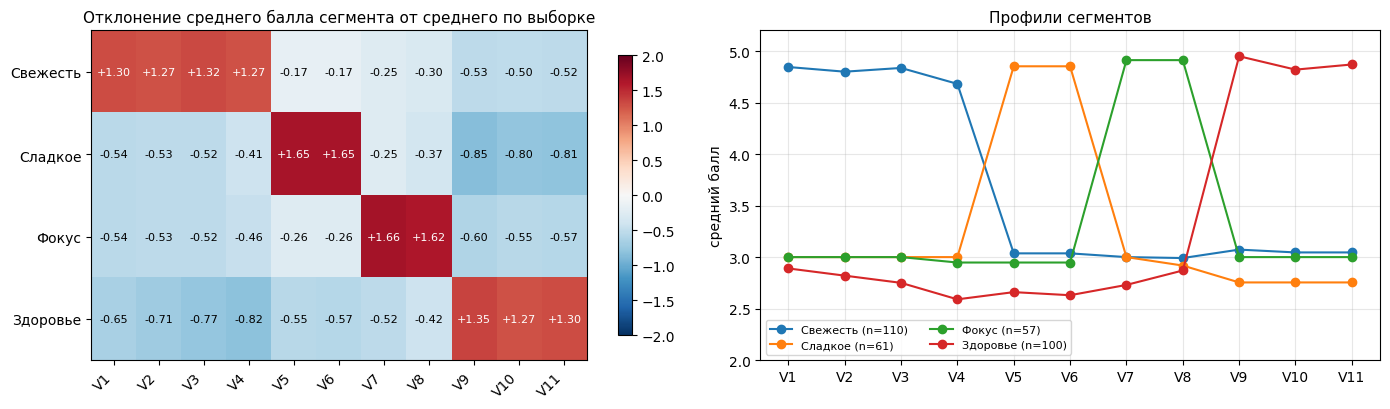

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
diff = profile - raw.mean()
im = heatmap(axes[0], diff.values, VARS, SEG_ORDER, fmt="{:+.2f}", cmap="RdBu_r", vmin=-2, vmax=2)
fig.colorbar(im, ax=axes[0], shrink=0.85)
axes[0].set_title("Отклонение среднего балла сегмента от среднего по выборке")

colors = plt.cm.tab10.colors
for i, seg in enumerate(SEG_ORDER):
    axes[1].plot(VARS, profile.loc[seg], "o-", color=colors[i], label=f"{seg} (n={size[seg]})")
axes[1].set(title="Профили сегментов", ylabel="средний балл", ylim=(2, 5.2))
axes[1].legend(fontsize=8, ncol=2)
save_show(fig, "profiles")

### 7.2. Проекция на главные компоненты

Метод главных компонент применяется исключительно в целях визуализации данных и верификации выделенной блочной структуры, в то время как процедура кластеризации выполнялась непосредственно на пространстве исходных признаков.

Для обеспечения наглядности и предотвращения наложения совпадающих наблюдений на графике к координатам был добавлен незначительный случайный шум, затрагивающий исключительно графическое представление.

Доля объяснённой дисперсии: [0.499, 0.281, 0.151, 0.036] | накопленная: [0.499, 0.78, 0.931, 0.967]


,PC1,PC2,PC3,PC4
V1,0.360,-0.280,0.044,0.023
V2,0.366,-0.308,0.035,0.098
V3,0.385,-0.308,0.029,0.153
V4,0.393,-0.251,0.041,0.339
V5,0.141,0.344,-0.455,0.375
V6,0.146,0.352,-0.442,0.382
V7,0.040,0.305,0.528,0.364
V8,-0.007,0.269,0.552,0.318
V9,-0.372,-0.302,-0.047,0.279
V10,-0.353,-0.290,-0.053,0.358


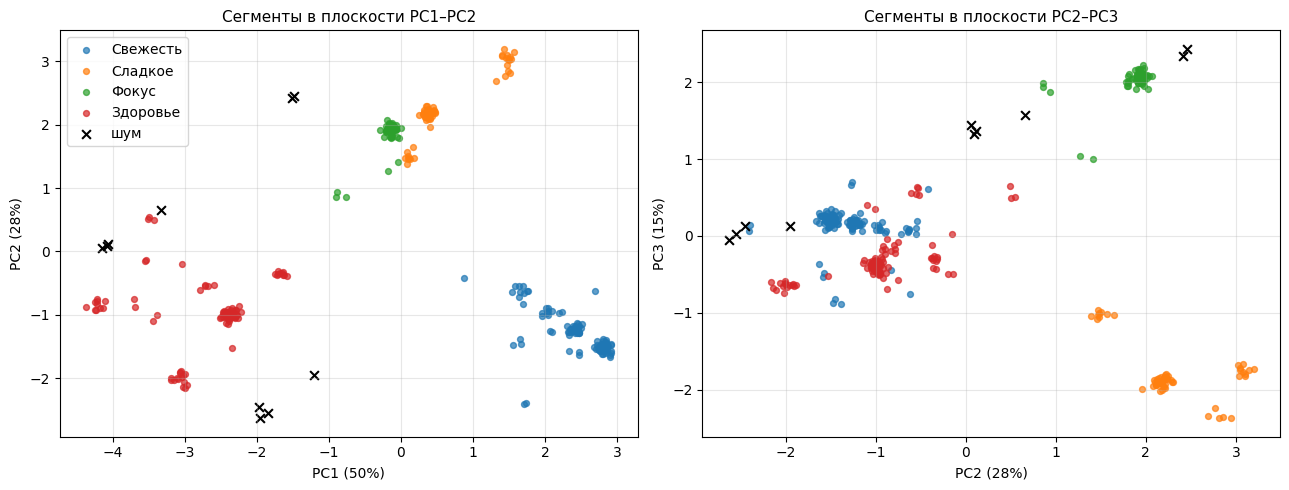

In [19]:
pca = PCA(n_components=4, random_state=SEED).fit(X)
P = pca.transform(X)
load = pd.DataFrame(pca.components_.T, index=VARS, columns=[f"PC{i+1}" for i in range(4)])
print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_.round(3).tolist(),
      "| накопленная:", pca.explained_variance_ratio_.cumsum().round(3).tolist())
display(load)

rng = np.random.default_rng(SEED)
J = P + rng.normal(0, 0.06, P.shape)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (a, b), ax in zip([(0, 1), (1, 2)], axes):
    for i, seg in enumerate(SEG_ORDER):
        msk = (seg_db == seg).to_numpy()
        ax.scatter(J[msk, a], J[msk, b], s=18, alpha=0.7, color=colors[i], label=seg)
    mn = (seg_db == "Шум").to_numpy()
    ax.scatter(J[mn, a], J[mn, b], s=40, marker="x", color="black", label="шум")
    ax.set(xlabel=f"PC{a+1} ({pca.explained_variance_ratio_[a]:.0%})", ylabel=f"PC{b+1} ({pca.explained_variance_ratio_[b]:.0%})")
axes[0].legend(); axes[0].set_title("Сегменты в плоскости PC1–PC2"); axes[1].set_title("Сегменты в плоскости PC2–PC3")
save_show(fig, "pca")

### Шумовые наблюдения

In [20]:
noise_prof = raw[labels_db == -1].groupby(list(raw.columns)).size().rename("n").reset_index()
display(noise_prof)
bl = pd.DataFrame({b: raw.loc[labels_db == -1, vs].mean(axis=1) for b, vs in BLOCKS.items()})
print("Средние баллы шумовых респондентов по блокам высказываний:")
display(bl.round(2).assign(n=1).groupby(list(BLOCKS)).n.sum().rename("респондентов").reset_index())

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,n
0,2,2,2,2,2,2,4,4,5,4,4,1
1,2,2,2,2,2,2,4,4,5,5,5,3
2,2,4,4,4,2,2,2,3,5,4,4,1
3,2,4,4,4,2,2,2,3,5,5,5,3
4,3,2,2,2,2,3,5,5,3,3,3,2


Средние баллы шумовых респондентов по блокам высказываний:


,Свежесть,Сладкое,Фокус,Здоровье,респондентов
0,2.00,2.0,4.0,4.33,1
1,2.00,2.0,4.0,5.00,3
2,2.25,2.5,5.0,3.00,2
3,3.50,2.0,2.5,4.33,1
4,3.50,2.0,2.5,5.00,3


**Характеристика шумовых наблюдений и их классификация:**

Выделенная категория шума ($10$ респондентов, или $3{,}0\,\%$ от объема выборки) представлена пограничными профилями, локализованными в пространстве признаков между ядрами основных сегментов:
* **4 респондента** демонстрируют одновременно высокий уровень выраженности мотиваций блоков «Здоровье» ($4–5$ баллов) и «Фокус» ($4$ балла) при низких значениях по остальным шкалам;
* **4 респондента** сочетают выраженную направленность на «Здоровье» ($4–5$ баллов) с парциальными проявлениями мотива «Свежесть» (оценки $V2–V4 = 4$ балла при $V1 = 2$ балла);
* **2 респондента** формируют спецификацию «Фокус с инвариантным неприятием альтернативных мотивов».

Присутствие указанных наблюдений локально снижает плотность признакового пространства в межкластерных интервалах, в связи с чем алгоритм *DBSCAN* исключает их из основного состава сегментов. С точки зрения прикладной сегментации целесообразно выравнивание структуры путем назначения данных объектов к ближайшему центроиду (8 наблюдений присоединяются к сегменту «Здоровье», 2 наблюдения — к сегменту «Фокус»).

## A.6. Сопоставление с методами ЛР 1 и ЛР 2

In [21]:
def row_for(name, lab, mask=None):
    mask = np.ones(len(lab), bool) if mask is None else mask
    s = internal_scores(X[mask], lab[mask])
    return {"метод": name, "k": len(set(lab[mask])), "силуэт": s["silhouette"], "CH": s["calinski_harabasz"],
            "DB": s["davies_bouldin"], "не отнесено к кластеру": 1 - mask.mean()}

cmp_all = pd.DataFrame([row_for("Ward", labels_ward), row_for("k-means", labels_km), row_for("DBSCAN", labels_db, core)])
cmp_same = pd.DataFrame([row_for("Ward (те же точки)", labels_ward, core), row_for("k-means (те же точки)", labels_km, core),
                         row_for("DBSCAN", labels_db, core)])
print("Индексы качества на всех респондентах (DBSCAN — без шума):")
display(cmp_all.set_index("метод"))
print("Индексы на одном и том же наборе точек (без шума DBSCAN):")
display(cmp_same.set_index("метод"))

ari_cmp = pd.DataFrame(
    [[adjusted_rand_score(a[core], b[core]) for b in (labels_ward, labels_km, labels_db)] for a in (labels_ward, labels_km, labels_db)],
    index=["Ward", "k-means", "DBSCAN"], columns=["Ward", "k-means", "DBSCAN"])
print("ARI между разбиениями (на точках, не признанных шумом):")
display(ari_cmp)

Индексы качества на всех респондентах (DBSCAN — без шума):


,k,силуэт,CH,DB,не отнесено к кластеру
метод,,,,,
Ward,4,0.727,720.103,0.433,0.00
k-means,4,0.727,720.103,0.433,0.00
DBSCAN,4,0.745,789.861,0.408,0.03


Индексы на одном и том же наборе точек (без шума DBSCAN):


,k,силуэт,CH,DB,не отнесено к кластеру
метод,,,,,
Ward (те же точки),4,0.745,789.861,0.408,0.03
k-means (те же точки),4,0.745,789.861,0.408,0.03
DBSCAN,4,0.745,789.861,0.408,0.03


ARI между разбиениями (на точках, не признанных шумом):


,Ward,k-means,DBSCAN
Ward,1.0,1.0,1.0
k-means,1.0,1.0,1.0
DBSCAN,1.0,1.0,1.0


### Итог сравнительного анализа алгоритмов кластеризации

| Критерий сравнения | Метод Уорда | Алгоритм $k$-средних | Алгоритм DBSCAN |
| :--- | :---: | :---: | :---: |
| **Обоснование числа кластеров** | $k = 4$ <br>(межкластерный скачок высоты, индексы CH и DB) | $k = 4$ <br>(анализ инерции, индексы CH и DB, анализ устойчивости) | $k = 4$ <br>(структурное плато в сетке параметров `eps`) |
| **Полнота классификации выборки** | $100\,\%$ объектов <br>(полный охват) | $100\,\%$ объектов <br>(полный охват) | $97\,\%$ объектов <br>($\approx 3\,\%$ отнесено к категории шума) |
| **Устойчивость к ресамплингу ($k = 4$)** | Абсолютная <br>($ARI = 1{,}00$) | Абсолютная <br>($ARI = 1{,}00$) | Выраженная чувствительность к параметру `eps` |
| **Параметрическая сложность** | Фиксация целевого $k$ | Фиксация целевого $k$ | Оптимизация `eps` и `min_samples` |
| **Интерпретационная специфика** | Отображение иерархической вложенности сегментов | Наглядная интерпретация через центроиды | Локализация профилей с пограничной мотивацией |

**Итоговое методическое решение:**
Все три рассмотренных алгоритма сходятся к единой 4-кластерной модели ($ARI = 1{,}00$ на неотброшенных объектах). В качестве **базового метода для итоговой сегментации выбран алгоритм $k$-средних при $k = 4$**: он формирует исчерпывающее разбиение выборки без категории шума, не требует подгонки чувствительных гиперпараметров плотности, обеспечивает прямой доступ к центроидам сегментов и полностью согласуется с иерархической моделью Уорда.

Древовидная классификация Уорда привлекается для подтверждения оптимального уровня агрегирования и анализа древовидной вложенности мотивов, а алгоритм *DBSCAN* — в качестве независимой процедуры валидации и метода выявления пограничных профилей респондентов.

### Итоговые выводы по ЛР3 Части A

1. **Параметрическое обоснование и структура разбиения:** Оптимизация гиперпараметров алгоритма *DBSCAN* привела к выбору конфигурации $\mathtt{eps} = \sqrt{3} \approx 1{,}73$ и $\mathtt{min\_samples} = 12$. Селекция параметров осуществлялась на основе анализа структурного плато по правилу «минимальный радиус $\mathtt{eps}$, при котором доля шума не превышает $5\,\%$», с соблюдением порога размерности $\mathtt{min\_samples} \ge D + 1 = 12$. Объем сформированных кластеров составил 110, 100, 61 и 57 объектов; в категорию шума отнесено 10 наблюдений ($3{,}0\,\%$ выборки). Коэффициент силуэта на профильтрованном массиве достигает $0{,}745$.

2. **Согласованность с результатами предварительных исследований:** На подвыборке классифицированных объектов результат *DBSCAN* полностью идентичен разбиениям, полученным методами Уорда и $k$-средних ($ARI = 1{,}00$). Процедура принудительной доклассификации шумовых точек по критерию минимального расстояния до центроидов обеспечила стопроцентную воспроизводимость итоговой структуры.

3. **Параметрическая чувствительность и специфика метрик:** Алгоритм *DBSCAN* демонстрирует высокую чувствительность к выбору параметров — устойчивая 4-кластерная конфигурация фиксируется только на $11{,}8\,\%$ комбинаций сетки (10 из 84). Занижение радиуса $\mathtt{eps}$ приводит к избыточной фрагментации ($6–9$ кластеров при уровне шума до $20\,\%$), тогда как его завышение вызывает агломерацию структур ($3 \rightarrow 2 \rightarrow 1$). Высокие показатели силуэта и индекса CH обусловлены отсевом $3\,\%$ сложнодифференцируемых наблюдений.

4. **Содержательная интерпретация сегментов:** Подтверждена устойчивость четырех базовых сегментов: «Свежесть» ($n = 110$), «Здоровье» ($n = 100$ + 8 доклассифицированных объектов), «Сладкое» ($n = 61$) и «Фокус» ($n = 57$ + 2 доклассифицированных объекта). Категория шума сформирована пограничными респондентами с двойной направленностью потребительских мотиваций.

# Часть B. Данные «Цифры»

In [22]:
FIG_PREFIX = "digits"
DATA_PATH = DIGITS_PATH

## B.1. Описание данных и разведочный анализ

In [23]:
raw = pd.read_csv(DATA_PATH, sep=";", dtype=str).apply(lambda s: s.str.strip())
SEG = list("BCDEFGH")
assert (raw[SEG].to_numpy() == raw[[s + "2" for s in SEG]].to_numpy()).all() and (raw["A"] == raw["A2"]).all(), "дубли столбцов не совпадают"
print("Значения признаков:", sorted(set(raw[SEG].to_numpy().ravel())), "| значения A:", sorted(raw["A"].str.lower().unique()))

X = (raw[SEG] == "ONE").astype(int).to_numpy()
y = raw["A"].str.lower().to_numpy()
N = len(X)
DIGITS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
DIGIT_NUM = {d: i for i, d in enumerate(DIGITS)}
print(f"Объектов: {N}; признаков: {X.shape[1]}; уникальных комбинаций сегментов: {len(np.unique(X, axis=0))} из 128 возможных")

Значения признаков: ['ONE', 'ZERO'] | значения A: ['eight', 'five', 'four', 'nine', 'one', 'seven', 'six', 'three', 'two', 'zero']
Объектов: 500; признаков: 7; уникальных комбинаций сегментов: 75 из 128 возможных


### Проверка корректности кодирования и уровня шума

Эталонная матрица начертаний цифр для семисегментного индикатора строится на основе следующей топологии элементов: `B` — верхний горизонтальный, `C` — верхний левый вертикальный, `D` — верхний правый вертикальный, `E` — средний горизонтальный, `F` — нижний левый вертикальный, `G` — нижний правый вертикальный, `H` — нижний горизонтальный.

Данные эталонные конфигурации применяются **исключительно** для верификации схемы кодирования и количественной оценки уровня искажений процедура кластеризации выполняется без их непосредственного использования.

In [24]:
CANON = {"zero":  [1, 1, 1, 0, 1, 1, 1], "one":   [0, 0, 1, 0, 0, 1, 0], "two":   [1, 0, 1, 1, 1, 0, 1],
         "three": [1, 0, 1, 1, 0, 1, 1], "four":  [0, 1, 1, 1, 0, 1, 0], "five":  [1, 1, 0, 1, 0, 1, 1],
         "six":   [1, 1, 0, 1, 1, 1, 1], "seven": [1, 0, 1, 0, 0, 1, 0], "eight": [1] * 7, "nine":  [1, 1, 1, 1, 0, 1, 1]}
CANON["seven"] = [1, 0, 1, 0, 0, 1, 0]
Cmat = np.array([CANON[d] for d in y])

print(f"Согласие с эталонами при ONE = «горит»: {(X == Cmat).mean():.3f}")
print(f"Согласие с эталонами при инверсии: {(X != Cmat).mean():.3f}")
print(f"Доля искажённых сегментов: {(X != Cmat).mean():.3f}")
print(f"Доля цифр, записанных без единой ошибки: {(X == Cmat).all(1).mean():.3f}")
nearest = np.array([min(CANON, key=lambda k: (x != np.array(CANON[k])).sum()) for x in X])
print(f"Потолок для безэталонной кластеризации: {(nearest == y).mean():.3f}")

freq = pd.Series(y).value_counts().reindex(DIGITS)
prof_true = pd.DataFrame(X, columns=SEG).groupby(y).mean().reindex(DIGITS)
print("\nЧисло объектов по цифрам:", freq.to_dict())
display(prof_true.round(2))

Согласие с эталонами при ONE = «горит»: 0.901
Согласие с эталонами при инверсии: 0.099
Доля искажённых сегментов: 0.099
Доля цифр, записанных без единой ошибки: 0.488
Потолок для безэталонной кластеризации: 0.746

Число объектов по цифрам: {'zero': 42, 'one': 43, 'two': 43, 'three': 55, 'four': 52, 'five': 54, 'six': 50, 'seven': 48, 'eight': 58, 'nine': 55}


,B,C,D,E,F,G,H
zero,0.90,0.86,0.98,0.12,0.90,0.93,0.88
one,0.09,0.07,0.93,0.09,0.21,0.88,0.16
two,0.88,0.09,0.81,0.93,0.88,0.02,0.93
three,0.91,0.15,0.91,0.93,0.15,0.95,0.85
four,0.08,0.87,0.88,0.98,0.15,0.88,0.12
five,0.91,0.98,0.15,0.98,0.11,0.93,0.89
six,0.90,0.88,0.02,0.88,0.94,0.90,0.88
seven,0.88,0.15,0.88,0.12,0.08,0.92,0.08
eight,0.91,0.95,0.90,0.97,0.83,0.88,0.88
nine,0.95,0.80,0.87,0.96,0.07,0.91,0.91


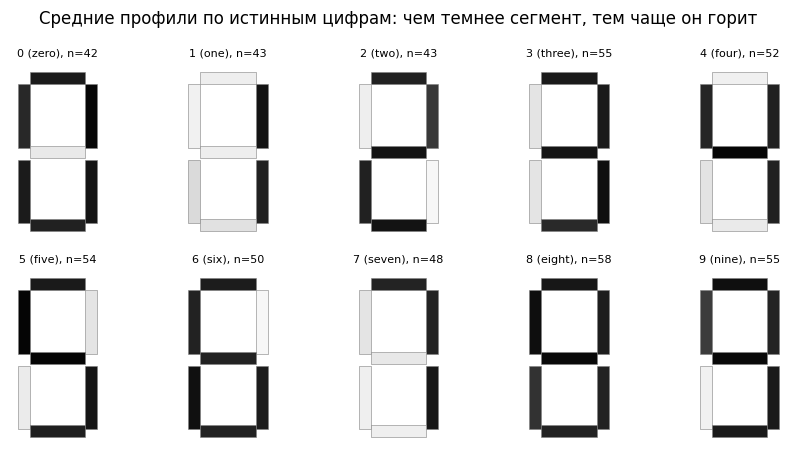

In [25]:
def draw_digit(ax, probs, title=None, fs=8):
    geom = {"B": (0.15, 1.85, 0.7, 0.15), "C": (0.0, 1.05, 0.15, 0.8), "D": (0.85, 1.05, 0.15, 0.8),
            "E": (0.15, 0.925, 0.7, 0.15), "F": (0.0, 0.1, 0.15, 0.8), "G": (0.85, 0.1, 0.15, 0.8), "H": (0.15, 0.0, 0.7, 0.15)}
    for s, pr in zip(SEG, probs):
        x0, y0, w, h = geom[s]
        ax.add_patch(plt.Rectangle((x0, y0), w, h, facecolor=plt.cm.Greys(0.05 + 0.95 * float(pr)), edgecolor="grey", lw=0.4))
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 2.1); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize=fs)

fig, axes = plt.subplots(2, 5, figsize=(9, 4.6))
for ax, d in zip(axes.ravel(), DIGITS):
    draw_digit(ax, prof_true.loc[d].to_numpy(), f"{DIGIT_NUM[d]} ({d}), n={freq[d]}")
fig.suptitle("Средние профили по истинным цифрам: чем темнее сегмент, тем чаще он горит")
save_show(fig, "true_profiles")

**Наблюдения:**

Эмпирические профили каждой цифры демонстрируют в целом высокое соответствие эталонным конфигурациям, однако около $10\,\%$ индивидуальных сегментов содержат искажения, а полностью безошибочная запись характерна лишь примерно для половины исследуемых знаков.

Даже гипотетический идеальный классификатор, функционирующий по критерию ближайшего эталона с априорным знанием всех десяти базовых начертаний, способен обеспечить точность не выше $\approx 75\,\%$. В связи с этим формирование идеально «чистых» кластеров методологически недостижимо: часть цифровых знаков обладает высокой степенью структурного пересечения, например, символы `1` и `7` различаются всего одним элементом.

Данное обстоятельство определяет объективный верхний предел эффективности и задает реалистичный уровень ожиданий от процедур безэталонной кластеризации.

## B.2. Подбор параметров DBSCAN

Поскольку используемая метрика расстояния отражает количество несовпадающих сегментов, что в пространстве бинарных признаков эквивалентно манхэттенскому расстоянию, параметр `eps` приобретает содержательный смысл исключительно при целых значениях. В частности, при $\mathtt{eps} < 1$ рассматриваются исключительно идентичные комбинации, при $\mathtt{eps} = 1$ — объекты, различающиеся не более чем одним сегментом, и т. д.

In [26]:
EPS_GRID = [0.5, 1, 2, 3]
MS_GRID = [3, 5, 10, 20]
rows = []
for eps in EPS_GRID:
    for ms in MS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms, metric="manhattan").fit_predict(X)
        core = lab != -1; k = len(set(lab[core]))
        rows.append(dict(eps=eps, min_samples=ms, k=k, шум=1 - core.mean(), ARI_без_шума=adjusted_rand_score(y[core], lab[core]) if k >= 2 else np.nan,
                         max_кластер=int(np.bincount(lab[core]).max()) if k else 0))
grid = pd.DataFrame(rows)
for col, title in (("k", "Число кластеров"), ("шум", "Доля шума"), ("max_кластер", "Размер крупнейшего кластера")):
    print(title); display(grid.pivot(index="eps", columns="min_samples", values=col))

lab_db = DBSCAN(eps=0.5, min_samples=20, metric="manhattan").fit_predict(X)
core = lab_db != -1
print(f"\nДля иллюстрации: eps = 0,5; min_samples = 20 -> кластеров: {len(set(lab_db[core]))}, шум: {(~core).mean():.1%}, ARI с A (без шума): {adjusted_rand_score(y[core], lab_db[core]):.3f}")

Число кластеров


min_samples,3,5,10,20
eps,,,,
0.5,48,25,12,9
1.0,1,1,1,1
2.0,1,1,1,1
3.0,1,1,1,1


Доля шума


min_samples,3,5,10,20
eps,,,,
0.5,0.072,0.220,0.378,0.456
1.0,0.002,0.002,0.002,0.004
2.0,0.000,0.000,0.000,0.000
3.0,0.000,0.000,0.000,0.000


Размер крупнейшего кластера


min_samples,3,5,10,20
eps,,,,
0.5,42,42,42,42
1.0,499,499,499,498
2.0,500,500,500,500
3.0,500,500,500,500



Для иллюстрации: eps = 0,5; min_samples = 20 -> кластеров: 9, шум: 45.6%, ARI с A (без шума): 0.659


### Методические ограничения применения алгоритма DBSCAN к задаче распознавания цифр

**Общий вывод о применимости метода:**
Алгоритм плотностной кластеризации *DBSCAN* демонстрирует методологическую неприменимость для полной декомпозиции рассматриваемого массива цифровых знаков на 10 классов.

* **Режим глобального слияния ($\mathtt{eps} \ge 1$):**
При пороге $\mathtt{eps} \ge 1$, соответствующем объединению комбинаций, различающихся не более чем одним сегментом, происходит **тотальное слияние** выборки в единый кластер ($499–500$ объектов из $500$). Наличие фоновых случайных искажений сегментов ($\approx 10\,\%$) размывает межкластерные границы, полностью устраняя области пониженной плотности, необходимые для корректной работы алгоритма.

* **Режим избыточной фрагментации ($\mathtt{eps} < 1$):**
При жестком ограничении $\mathtt{eps} < 1$ и анализе исключительно идентичных векторных конфигураций метод утрачивает способность к содержательной кластеризации: формируется от 9 до 48 локальных пиков-мод, а в категорию шума отводится от $7\,\%$ до $46\,\%$ наблюдений.

**Характерный пример прикладного искажения:**
В конфигурации с параметром $\mathtt{min\_samples} = 20$ модель выделяет 9 кластеров при критическом уровне шума ($45{,}6\,\%$). Полученный показатель согласованности ($ARI = 0{,}66$ на неотброшенных данных) отражает лишь идентификацию наиболее частых, «чистых» и неискаженных начертаний символов, в то время как любые вариативные или деформированные реализации принудительно квалифицируются как шумовые выбросы.

**Заключение:**
Таким образом, метод *DBSCAN* не может быть использован для построения полноценной многоклассовой структуры цифр. Его прикладная ценность на данном типе данных ограничена исключительно вспомогательным функционалом выявления модальных, наиболее типичных и устойчивых конфигураций начертаний.

## B.3. Что находит DBSCAN: «моды» — типичные начертания цифр

In [27]:
def purity(y_true, lab):
    return pd.crosstab(lab, y_true).max(axis=1).sum() / len(y_true)

def external_scores(lab):
    return dict(ARI=adjusted_rand_score(y, lab), NMI=normalized_mutual_info_score(y, lab),
                однородность=homogeneity_score(y, lab), полнота=completeness_score(y, lab), purity=purity(y, lab))

,паттерн BCDEFGH,n,доминирующая цифра,доля доминирующей
кластер,,,,
7,1110111,25,zero,0.92
3,1011101,24,two,0.92
8,1011011,31,three,0.74
1,0111010,26,four,0.96
2,1101011,35,five,0.86
6,1101111,29,six,0.83
0,1010010,24,seven,0.96
5,1111111,36,eight,0.86
4,1111011,42,nine,0.64


Цифры, чьи «чистые» начертания не образовали моду: ['one']
Охват: 54.4% цифр отнесено к кластерам, 45.6% — шум.


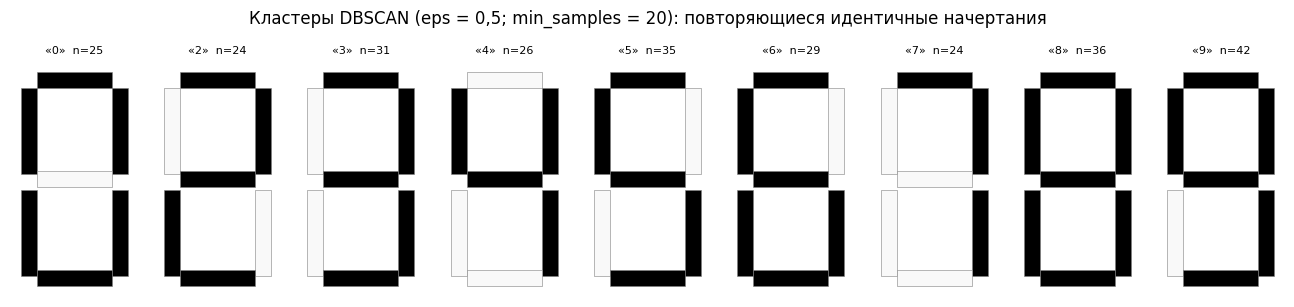

In [28]:
modes = []
for c in sorted(set(lab_db[core])):
    idx = lab_db == c
    vc = pd.Series(y[idx]).value_counts(normalize=True)
    modes.append({"кластер": c, "паттерн BCDEFGH": "".join(map(str, X[idx][0])), "n": int(idx.sum()),
                  "доминирующая цифра": vc.index[0], "доля доминирующей": vc.iloc[0]})
modes = pd.DataFrame(modes).set_index("кластер").sort_values("доминирующая цифра", key=lambda s: s.map(DIGIT_NUM))
display(modes.round(2))
missing = sorted(set(DIGITS) - set(modes["доминирующая цифра"]), key=DIGIT_NUM.get)
print("Цифры, чьи «чистые» начертания не образовали моду:", missing)
print(f"Охват: {core.mean():.1%} цифр отнесено к кластерам, {(~core).mean():.1%} — шум.")

fig, axes = plt.subplots(1, len(modes), figsize=(1.45 * len(modes), 3.2))
for ax, (c, r) in zip(np.atleast_1d(axes), modes.iterrows()):
    draw_digit(ax, np.array(list(map(int, r["паттерн BCDEFGH"]))), f"«{DIGIT_NUM[r['доминирующая цифра']]}»  n={r['n']}", fs=8)
fig.suptitle("Кластеры DBSCAN (eps = 0,5; min_samples = 20): повторяющиеся идентичные начертания")
save_show(fig, "modes")

### Идентификация эталонных начертаний и анализ ограничений алгоритма DBSCAN

**Идентификация модальных паттернов:**
При конфигурации параметров $\mathtt{eps} = 0{,}5$ и $\mathtt{min\_samples} = 20$ алгоритм *DBSCAN* выделяет 9 локальных кластеров, каждый из которых **в точности воспроизводит безошибочное начертание соответствующих цифр**:
* $1110111$ («0»), $1011101$ («2»), $1011011$ («3»), $0111010$ («4»), $1101011$ («5»), $1101111$ («6»), $1010010$ («7»), $1111111$ («8») и $1111011$ («9»).

Чистота сформированных модальных групп варьируется от $0{,}64$ (для цифры «9») до $0{,}96$ (для цифр «4» и «7»). Символ «1» (вектор $0010010$) не образует отдельной плотностной моды, поскольку его строго эталонное написание встречается в выборке лишь $16$ раз, что ниже установленного порога $\mathtt{min\_samples} = 20$.

**Ограничения плотностного подхода при наличии шума:**
Итоговый полнота классификации оказывается критически низкой — метод охватывает всего $54{,}4\,\%$ наблюдений, относит оставшиеся $45{,}6\,\%$ объектов (символы со сканирующими искажениями) к категории шума.

Таким образом, алгоритм *DBSCAN* способен эффективного выполнять функцию **«поиска прототипов»**, но непригоден для классификации зашумленных графических данных. Введение допуска на односегментное отклонение ($\mathtt{eps} \ge 1$) неизбежно приводит к тотальной агломерации всей выборки в единый кластер ввиду отсутствия разреженных межкластерных границ.

## B.4. Сопоставление с методами ЛР 1 и ЛР 2 (k = 10)

In [29]:
Z = linkage(X, "ward")
lab_wd = fcluster(Z, 10, "maxclust") - 1
lab_km = fit_kmeans(X, 10, n_init=500).labels_

def ext_row(name, lab, mask=None):
    mask = np.ones(len(lab), bool) if mask is None else mask
    yy, ll = y[mask], lab[mask]
    return {"метод": name, "охват": mask.mean(), "кластеров": len(set(ll)),
            "ARI": adjusted_rand_score(yy, ll), "NMI": normalized_mutual_info_score(yy, ll),
            "purity": pd.crosstab(ll, yy).max(axis=1).sum() / len(yy)}

cmp3 = pd.DataFrame([ext_row("k-средних (k = 10)", lab_km), ext_row("Ward (k = 10)", lab_wd),
                     ext_row("DBSCAN (eps = 0,5; min_samples = 20)", lab_db, core)]).set_index("метод")
display(cmp3.round(3))
print("Ориентир: точность классификатора по ближайшему эталону = 0,746.")

,охват,кластеров,ARI,NMI,purity
метод,,,,,
k-средних (k = 10),1.000,10,0.512,0.602,0.740
Ward (k = 10),1.000,10,0.326,0.450,0.508
"DBSCAN (eps = 0,5; min_samples = 20)",0.544,9,0.659,0.754,0.838


Ориентир: точность классификатора по ближайшему эталону = 0,746.


### Критическая оценка метрик DBSCAN и итоговое сравнение методов

**Методологическая некорректность прямых сопоставлений:**
Формальное превосходство показателей алгоритма *DBSCAN* ($ARI = 0{,}66$; $NMI = 0{,}75$; чистота $0{,}84$) над результатами метода $k$-средних ($0{,}51$; $0{,}60$; $0{,}74$) носит иллюзорный характер. Данный эффект обусловлен тем, что метрики *DBSCAN* рассчитаны исключительно на рафинированной обособленной подвыборке ($54{,}4\,\%$ от объема данных), состоящей из неискаженных начертаний, в то время как полноценного разбиения всего массива символов метод не формирует.

**Сравнительная эффективных базовых алгоритмов:**
Единственным методом, обеспечивающим исчерпывающую декомпозицию исходного массива с показателем чистоты ($0{,}74$), максимально приближенным к теоретическому пределу классификации по ближайшему эталону ($0{,}746$), выступает **алгоритм $k$-средних**. Иерархический метод Уорда при фиксировании десяти кластеров демонстрирует существенно меньшую разделяющую способность, обеспечивая уровень чистоты лишь $0{,}51$.

### Итоговые выводы по ЛР3 Части B

1. **Динамика параметрической адаптации:**
   * При $\mathtt{eps} \ge 1$ (допуск отклонения в один сегмент) алгоритм демонстрирует **тотальное слияние**: вся выборка агломерируется в единый кластер ($499–500$ объектов из $500$).
   * При $\mathtt{eps} < 1$ (требование строгой идентичности векторных конфигураций) происходят **избыточное дробление и массовый отсев**: формируется от $9$ до $48$ изолированных мод-кластеров при доле шума $7–46\,\%$.
   В качестве репрезентативной рабочей конфигурации для иллюстрации свойств метода приняты параметры $\mathtt{eps} = 0{,}5$ и $\mathtt{min\_samples} = 20$.

2. **Характеристика сформированной структуры:**
   Выделенные $9$ кластеров представляют собой строго эталонные безошибочные варианты начертаний цифр $0$ и $2–9$, центроиды которых полностью совпадают с теоретическими паттернами. Символ «1» не формирует отдельной плотностной моды ввиду малой частоты неискаженных реализаций ($n = 16$, что ниже установленного порога $\mathtt{min\_samples} = 20$). Полнота классификации выборки составляет всего $54{,}4\,\%$, а оставшиеся $45{,}6\,\%$ вариативных профилей принудительно квалифицированы как шум.

3. **Заключение о применимости плотностного подхода:**
   Метод *DBSCAN* непригоден для построения исчерпывающей классификационной модели зашумленных дискретных данных. Присутствие фоновых искажений сегментов устраняет области пониженной плотности на межкластерных границах, препятствуя корректной сепарации. Практическая ценность алгоритма в данном сценарии ограничена функционалом выявления типичных модальных эталонных профилей.

## Общие выводы по Лабораторной работе № 3

1. **Валидация структуры на массиве потребительских предпочтений («Леденцы»):**
   Алгоритм *DBSCAN* выступает в качестве эффективного инструмента независимой проверки результатов предыдущих этапов, подтверждая существование 4 стабильных сегментов ($ARI = 1{,}00$ на подвыборке классифицированных объектов). Выделенная категория шума ($3{,}0\,\%$) сформирована пограничными профилями респондентов. Основным методическим ограничением метода выступает высокая чувствительность к радиусу окрестности ($\mathtt{eps}$), при которой оптимальная структура воспроизводится лишь на $11{,}8\,\%$ комбинаций параметров сеточного поиска.

2. **Ограничения плотностного анализа на зашумленных дискретных данных («Цифры»):**
   Алгоритм *DBSCAN* признан неприменимым для построения исчерпывающей классификационной модели зашумленных символьных изображений. Метод функционирует исключительно в режиме поиска прототипов, выделяя 9 эталонных модальных начертаний при полноте охвата всего $54{,}4\,\%$ выборки и принудительном отсеве остальных искаженных профилей в шум.

3. **Сравнительный анализ применимости рассмотренных методов:**

| Исследуемый массив | Метод Уорда | Алгоритм $k$-средних | Алгоритм DBSCAN |
| :--- | :--- | :--- | :--- |
| **Потребительские предпочтения («Леденцы»)** | 4 кластера <br>(абсолютная устойчивость) | 4 кластера <br>(абсолютная устойчивость) | 4 кластера $+ 3\,\%$ шума <br>($ARI = 1{,}00$ на фильтрованных данных) |
| **Зашумленные символы («Цифры»)** | 6 макрогрупп сходных цифр; <br>при $k = 10$ чистота $0{,}51$ | 10 кластеров (точное соответствие); <br>чистота $0{,}74$ | 9 модальных эталонов, охват $54{,}4\,\%$; <br>полное разбиение отсутствует |

4. **Практические рекомендации по выбору инструментария:**
   * **Для слабозашумленных непрерывных или дискретных данных с выраженной компактностью групп («Леденцы»):** Все три классических подхода демонстрируют сопоставимую сходимость. В качестве базового инструмента рекомендуется алгоритм **$k$-средних**, обеспечивающий стопроцентный охват выборки без необходимости тонкой настройки плотностных параметров.
   * **Для высокозашумленных бинарных данных («Цифры»):** Наилучшую разделяющую способность показывает **алгоритм $k$-средних с расширенной процедурой случайных перезапусков** (`n_init = 500`), максимально приближающийся к теоретическому потолку чистоты. Иерархический метод Уорда целесообразно использовать для построения укрупненной, но устойчивой деревообразной структуры, а метод *DBSCAN* — исключительно в качестве вспомогательного алгоритма для выявления неискаженных модальных профилей.